# De una PD al capital: la función IRB, la cartera homogénea grande y la cartera TTC

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 y 05 de este tema (una PD por grado y el precio de una calibración)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué es la cartera homogénea grande (LHP), y leer su distribución, sus cuantiles y el factor que implica una tasa de incumplimiento observada;
- llevar una exposición por la función IRB de Basilea III con cada intermedio impreso (la correlación de activos, la PD condicional al 99,9%, el ajuste por vencimiento, K y el ponderador de riesgo), y verificarla contra el cuantil de la LHP;
- comparar cuatro regímenes regulatorios sobre la misma exposición y decir cuáles de sus diferencias son el piso de PD y cuáles el factor 1,06 de Basilea II;
- convertir las PD de largo plazo de una agencia calificadora en el ponderador de riesgo medio de una cartera, y ver dónde el piso de PD obliga;
- explicar por qué una proyección con una matriz de migración deriva hacia una cartera propia, y leer la deriva en las trayectorias impresas de Engelmann y en la matriz de S&P.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.engines import vasicek
from riskvalidation.regulatory import irb
from riskvalidation.transitions import ttc
from scipy.special import ndtri

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres archivos versionados, de los casos C04 y C01 (https://registers.esma.europa.eu/cerep-publication/ para las cohortes de S&P, clase de licencia `mirror-allowed`):

- `data/derived/C04/sp.json`: las PD de largo plazo de S&P por grado bajo dos definiciones de incumplimiento (`outputs.lra.d2`, `outputs.lra.d4`), las 26 cohortes con sus tamaños (la mezcla de grados de la cartera), la matriz agrupada, la mezcla de origen, los supuestos IRB del caso (`outputs.irb`) y los ponderadores de riesgo versionados de la mezcla de cohortes (`impact.rw_d2`, `impact.rw_d4`).
- `data/derived/C04/published.json`: el portafolio TTC impreso de Engelmann (2024) y las trayectorias impresas a 50 años de cuatro portafolios iniciales (`outputs.engelmann`).
- `data/derived/C01/holdout.json`: la grilla de paridad IRB del caso C01, 162 ponderadores de riesgo de exposiciones minoristas bajo tres regímenes (`outputs.irb.parity`).

Los supuestos IRB de C04 son los de Basilea III final para una exposición corporativa: LGD 45% (el valor F-IRB para créditos senior sin garantía contra instituciones financieras, CRE32.6; los demás corporativos tienen 40%), usada con la correlación de los corporativos no financieros y sin el multiplicador de 1,25 de CRE31.7, que es el supuesto del caso, vencimiento 2,5 años (CRE32.44) y piso de PD de 0,05% (CRE32.4); el marco está en https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27. La celda siguiente carga los archivos y los imprime.

In [2]:
# Cargar los tres artefactos (el cuaderno está tres carpetas bajo la raíz del repositorio) e imprimir los supuestos IRB
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
load = lambda case, name: json.loads((DERIVED / case / name).read_text(encoding="utf-8"))
sp, published, holdout = load("C04", "sp.json"), load("C04", "published.json"), load("C01", "holdout.json")
out = sp["outputs"]
grades, states = out["grades"], out["states"]
assumptions = out["irb"]

for label, doc in (("sp", sp), ("published", published), ("holdout", holdout)):
    print(f"{label:10s} calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("supuestos IRB de C04:", {k: v for k, v in assumptions.items() if k != "references"})
print("regímenes que conoce el motor:", list(irb.REGIMES))

sp         calculado con riskvalidation 1.0.1 | instalado 1.0.1
published  calculado con riskvalidation 1.0.1 | instalado 1.0.1
holdout    calculado con riskvalidation 1.0.1 | instalado 1.0.1
supuestos IRB de C04: {'regime': 'basel3', 'asset_class': 'corporate', 'lgd': 0.45, 'maturity': 2.5, 'pd_floor': 0.0005}
regímenes que conoce el motor: ['basel3', 'crr3', 'basel2', 'cl_ran21_6']


## Método

### Paso 1: la cartera homogénea grande

El modelo de un factor del cuaderno 01 da a cada deudor el retorno de activos $A = \sqrt{\rho}\,Z + \sqrt{1-\rho}\,\varepsilon$ y un incumplimiento cuando $A$ cae bajo $\Phi^{-1}(p)$. En una cartera de muchos deudores con la misma PD $p$ y correlación $\rho$, las partes idiosincráticas se promedian y la fracción de incumplimientos converge a la PD condicional $p(Z)$ (Vasicek, 2002; Gordy, 2003): la **cartera homogénea grande** (LHP). Su función de distribución y su cuantil $q$ son

$$P(L \le x) = \Phi\!\left(\frac{\sqrt{1-\rho}\,\Phi^{-1}(x) - \Phi^{-1}(p)}{\sqrt{\rho}}\right), \qquad L_q = \Phi\!\left(\frac{\Phi^{-1}(p) + \sqrt{\rho}\,\Phi^{-1}(q)}{\sqrt{1-\rho}}\right)$$

La PD condicional de la fórmula IRB es este cuantil en $q = 0{,}999$: la tasa de incumplimiento de la cartera en un año de uno en mil. El motor tiene las funciones en `engines.vasicek`. La celda siguiente toma la PD a través del ciclo de S&P de la mezcla de cohortes (cuaderno 01: 0,61%, versionada en `impact.ttc_default_rate`) con la correlación de activos corporativa de Basilea III a esa PD, imprime los cuantiles, verifica el viaje de ida y vuelta de la función de distribución, y lee el factor que implica la tasa de incumplimiento de la última cohorte (0,77%, `impact.latest_default_rate`).

In [3]:
# Cuantiles de la LHP de la PD a través del ciclo de S&P, el viaje de ida y vuelta de la función de distribución y el factor del último año
ttc_pd = sp["impact"]["ttc_default_rate"]["value"]
latest_rate = sp["impact"]["latest_default_rate"]["value"]
rho = irb.correlation("corporate", ttc_pd)
print("PD TTC:", round(ttc_pd, 6), "| correlación corporativa de Basilea III a esa PD:", round(rho, 4))

levels = np.array([0.5, 0.9, 0.99, 0.999])
quantiles = vasicek.lhp_quantile(levels, ttc_pd, rho)
print(f"{'q':>8s}{'tasa de incumplimiento de la cartera':>46s}{'veces la PD':>16s}{'P(L <= x)':>12s}")
for q, x in zip(levels, quantiles):
    print(f"{q:8.3f}{x:46.6f}{x / ttc_pd:16.2f}{float(vasicek.lhp_cdf(x, ttc_pd, rho)):12.6f}")
print("la función de distribución devuelve el nivel:", si_no(np.allclose(vasicek.lhp_cdf(quantiles, ttc_pd, rho), levels)))

z_latest = vasicek.implied_factor(latest_rate, ttc_pd, rho)
print("tasa de incumplimiento de la última cohorte:", round(latest_rate, 6), "| factor implícito:", round(float(z_latest), 3), "| de vuelta a la tasa:", round(float(vasicek.conditional_pd(ttc_pd, rho, z_latest)), 6))

PD TTC: 0.006097 | correlación corporativa de Basilea III a esa PD: 0.2085
       q          tasa de incumplimiento de la cartera     veces la PD   P(L <= x)
   0.500                                      0.002422            0.40    0.500000
   0.900                                      0.015402            2.53    0.900000
   0.990                                      0.052251            8.57    0.990000
   0.999                                      0.109090           17.89    0.999000
la función de distribución devuelve el nivel: sí
tasa de incumplimiento de la última cohorte: 0.0077 | factor implícito: -0.769 | de vuelta a la tasa: 0.0077


Un año del 99,9% lleva la tasa de incumplimiento de la cartera de 0,61% a cerca de 11%, dieciocho veces la PD. Esa cola, no el promedio, es lo que cubre el capital. La última cohorte queda en un factor de -0,77: algo peor que el ciclo promedio.

### Paso 2: una exposición por la función IRB

El requerimiento de capital IRB de Basilea III para una exposición no minorista (CRE31.5) es la pérdida en el año del 99,9% menos la pérdida esperada, con un ajuste por vencimiento:

$$K = \left[\mathrm{LGD}\,\Phi\!\left(\frac{\Phi^{-1}(\mathrm{PD}) + \sqrt{R}\,\Phi^{-1}(0{,}999)}{\sqrt{1-R}}\right) - \mathrm{PD}\cdot\mathrm{LGD}\right]\frac{1 + (M - 2{,}5)\,b}{1 - 1{,}5\,b}, \quad b = (0{,}11852 - 0{,}05478 \ln \mathrm{PD})^2$$

con la correlación de activos corporativa $R = 0{,}12\,\frac{1 - e^{-50\,\mathrm{PD}}}{1 - e^{-50}} + 0{,}24\left(1 - \frac{1 - e^{-50\,\mathrm{PD}}}{1 - e^{-50}}\right)$ (CRE31.5), que baja de 24% para un deudor muy seguro a 12% para uno muy riesgoso, y el ponderador de riesgo es $12{,}5\,K$ (una fracción de la exposición). El término entre corchetes es el cuantil de la LHP del Paso 1 con $q = 0{,}999$. El `capital_requirement` del motor devuelve un `IRBResult` con cada parámetro. La celda siguiente toma una exposición corporativa con PD 1%, LGD 45% y vencimiento 2,5 años, imprime el resultado, verifica la correlación contra su forma cerrada, y reconstruye $K$ desde el cuantil de la LHP y el ajuste por vencimiento del resultado: dos módulos del motor que deben coincidir.

In [4]:
# Una exposición corporativa por la función IRB del motor, con la verificación contra el cuantil de la LHP
pd_one, lgd, maturity = 0.01, 0.45, 2.5
result = irb.capital_requirement("corporate", pd_one, lgd, maturity=maturity, regime="basel3")
for field in ("pd_input", "pd_applied", "lgd", "maturity", "correlation", "maturity_adjustment", "k", "risk_weight"):
    print(f"{field:20s} {getattr(result, field):.6f}")
print("fuente del ponderador y de la correlación:", result.references["risk_weight"], result.references["correlation"])

closed_form = 0.12 * (1 - np.exp(-50 * pd_one)) / (1 - np.exp(-50)) + 0.24 * (1 - (1 - np.exp(-50 * pd_one)) / (1 - np.exp(-50)))
print("correlación: motor y forma cerrada:", round(result.correlation, 8), round(float(closed_form), 8))
conditional = float(vasicek.lhp_quantile(0.999, pd_one, result.correlation))
print("PD condicional al 99.9% (cuantil de la LHP):", round(conditional, 6), "| igual a la PD condicional de Vasicek en z = -Phi^-1(0.999):", si_no(np.isclose(conditional, vasicek.conditional_pd(pd_one, result.correlation, -ndtri(0.999)))))
k_rebuilt = lgd * (conditional - pd_one) * result.maturity_adjustment
print("K reconstruida desde el cuantil de la LHP:", round(k_rebuilt, 8), "| K del motor:", round(result.k, 8), "| igual:", si_no(np.isclose(k_rebuilt, result.k)))
print("ponderador de riesgo = 12.5 K:", round(12.5 * result.k, 6), "| capital por 100 de exposición (8% de los activos ponderados por riesgo):", round(100 * result.risk_weight * 0.08, 3))

pd_input             0.010000
pd_applied           0.010000
lgd                  0.450000
maturity             2.500000
correlation          0.192784
maturity_adjustment  1.259810
k                    0.073853
risk_weight          0.923168
fuente del ponderador y de la correlación: CRE31.5 CRE31.5
correlación: motor y forma cerrada: 0.19278368 0.19278368
PD condicional al 99.9% (cuantil de la LHP): 0.140273 | igual a la PD condicional de Vasicek en z = -Phi^-1(0.999): sí
K reconstruida desde el cuantil de la LHP: 0.07385344 | K del motor: 0.07385344 | igual: sí
ponderador de riesgo = 12.5 K: 0.923168 | capital por 100 de exposición (8% de los activos ponderados por riesgo): 7.385


### Paso 3: regímenes, pisos y el factor 1,06

El motor tiene cuatro regímenes (`irb.REGIMES`): Basilea III final, el CRR3 de la UE (Artículo 153), Basilea II como rigió hasta 2022, y los métodos internos del regulador chileno (RAN 21-6). Difieren en dos cosas que este cuaderno puede ver: el piso de PD (0,05% en Basilea III y CRR3, 0,03% en Basilea II) y el factor de escala 1,06 sobre los activos ponderados por riesgo, que existe en Basilea II (CRE30.4) y ni en Basilea III final ni en el CRR3 Artículo 153. La celda siguiente pone la misma exposición corporativa (LGD 45%, vencimiento 2,5) bajo los regímenes en tres PD: una bajo el piso de Basilea III, una intermedia y una alta. A la PD baja los pisos difieren y la razón no es 1,06; sobre ellos es exactamente 1,06.

In [5]:
# La misma exposición corporativa bajo los cuatro regímenes en tres PD, con la razón Basilea II sobre Basilea III
pds = (0.0004, 0.01, 0.10)
print(f"{'':12s}" + "".join(f"PD {p:<8.4f}" for p in pds) + f"{'piso de PD':>14s}{'escala':>10s}")
weights = {}
for regime_id, regime in irb.REGIMES.items():
    weights[regime_id] = [irb.capital_requirement("corporate", p, lgd, maturity=maturity, regime=regime_id).risk_weight for p in pds]
    print(f"{regime_id:12s}" + "".join(f"{w:<11.4f}" for w in weights[regime_id]) + f"{regime.pd_floor:14.4f}{regime.scaling:10.2f}")
print("Basel II / Basel III:", [round(float(b / a), 4) for a, b in zip(weights["basel3"], weights["basel2"])])
print("CRR3 / Basel III:", [round(float(b / a), 4) for a, b in zip(weights["basel3"], weights["crr3"])])

            PD 0.0004  PD 0.0100  PD 0.1000      piso de PD    escala
basel3      0.1965     0.9232     1.9309             0.0005      1.00
crr3        0.1965     0.9232     1.9309             0.0005      1.00
basel2      0.1821     0.9786     2.0467             0.0003      1.06
cl_ran21_6  0.1965     0.9232     1.9309             0.0005      1.00
Basel II / Basel III: [0.9267, 1.06, 1.06]
CRR3 / Basel III: [1.0, 1.0, 1.0]


El caso C01 versiona en el artefacto holdout una grilla de 162 ponderadores de riesgo minoristas (QRRE y otros minoristas, tres regímenes, seis PD, tres LGD). La celda siguiente recalcula cada punto con el motor e imprime la mayor diferencia, con la versión del motor que calculó la grilla junto a la instalada.

In [6]:
# Recalcular los 162 ponderadores de riesgo minoristas versionados con el motor e imprimir la mayor diferencia
grid = holdout["outputs"]["irb"]["parity"]
fresh = [irb.capital_requirement(p["asset_class"], p["pd"], p["lgd"], revolver=p["revolver"], regime=p["regime"]).risk_weight for p in grid]
diff = np.abs(np.array(fresh) - np.array([p["risk_weight"] for p in grid]))
print("calculado con riskvalidation", holdout["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("puntos:", len(grid), "| mayor diferencia:", f"{diff.max():.1e}")
sample = [p for p in grid if p["asset_class"] == "qrre" and p["revolver"] and p["pd"] == 0.02 and p["lgd"] == 0.5]
by_regime = {p["regime"]: p["risk_weight"] for p in sample}
print("QRRE revolvente, PD 2%, LGD 50%, ponderador por régimen:", {k: round(v, 4) for k, v in by_regime.items()})

calculado con riskvalidation 1.0.1 | instalado 1.0.1
puntos: 162 | mayor diferencia: 0.0e+00
QRRE revolvente, PD 2%, LGD 50%, ponderador por régimen: {'basel3': 0.3214, 'crr3': 0.3214, 'basel2': 0.3406}


### Paso 4: de las PD de largo plazo al ponderador de una cartera

El cuaderno 01 dio a cada grado su PD de largo plazo bajo dos definiciones de incumplimiento (`d2`, la página de incumplimientos de CEREP, y `d4`, su página de transiciones). La cartera es la mezcla de grados de las 26 cohortes, y su ponderador de riesgo medio es la suma de los ponderadores por grado ponderada por la mezcla. Los grados AAA, AA y A tienen PD de largo plazo bajo 0,05% (con `d4`: 0, 0,005% y 0,030%), así que el piso de PD obliga: su ponderador es el del piso. La celda siguiente calcula ambos ponderadores de la cartera con el motor y compara con los versionados `impact.rw_d2` e `impact.rw_d4`; la diferencia entre ambos es el tema del cuaderno 10.

In [7]:
# Ponderador IRB medio de la mezcla de cohortes de S&P bajo las dos definiciones de PD, con los grados que obliga el piso
mix = np.array([c["size"] for c in out["cohorts"]], dtype=float).sum(axis=0)
mix = mix / mix.sum()
risk_weight = lambda pd: irb.capital_requirement(assumptions["asset_class"], float(pd), assumptions["lgd"], maturity=assumptions["maturity"], regime=assumptions["regime"])
print("mezcla de grados de las 26 cohortes:", " ".join(f"{m:.4f}" for m in mix))
portfolio = {}
for definition in ("d2", "d4"):
    pds = np.array(out["lra"][definition]["rate"], dtype=float)
    results = [risk_weight(p) for p in pds]
    portfolio[definition] = float(np.sum(mix * np.array([r.risk_weight for r in results])))
    floored = [grades[i] for i, r in enumerate(results) if r.pd_applied != r.pd_input]
    print(f"{definition}: PD de largo plazo (%)", " ".join(f"{100 * p:.4f}" for p in pds), "| grados con piso de 0.05%:", ", ".join(floored))
    print(f"    ponderador por grado", " ".join(f"{r.risk_weight:.4f}" for r in results), "| cartera:", round(portfolio[definition], 6), "| versionado:", round(sp["impact"]["rw_" + definition]["value"], 6))
print("igual a los ponderadores versionados:", si_no(all(np.isclose(portfolio[d], sp["impact"]["rw_" + d]["value"], atol=1e-8) for d in portfolio)))
print("ponderador con d4 sobre d2:", round(portfolio["d4"] / portfolio["d2"], 4))

mezcla de grados de las 26 cohortes: 0.0105 0.1156 0.2551 0.2469 0.1482 0.1956 0.0282
d2: PD de largo plazo (%) 0.0000 0.0093 0.0350 0.1134 0.5299 2.9574 26.6369 | grados con piso de 0.05%: AAA, AA, A
    ponderador por grado 0.1965 0.1965 0.1965 0.3190 0.7146 1.2793 2.4793 | cartera: 0.579689 | versionado: 0.579689
d4: PD de largo plazo (%) 0.0000 0.0049 0.0305 0.0793 0.3363 1.3301 8.6084 | grados con piso de 0.05%: AAA, AA, A
    ponderador por grado 0.1965 0.1965 0.1965 0.2588 0.5760 1.0169 1.8255 | cartera: 0.474535 | versionado: 0.474535
igual a los ponderadores versionados: sí
ponderador con d4 sobre d2: 0.8186


### Paso 5: una proyección que deriva hacia una cartera propia

Un modelo de pruebas de estrés a menudo proyecta una cartera año tras año con una matriz de migración $T$, castiga la parte en incumplimiento y la reoriginan con un vector $O$ para mantener constante el saldo (Engelmann, 2024):

$$W_t' = W_{t-1}'\,T\,I_w + \bigl(W_{t-1}'\,T\,V_w\bigr)\,O'$$

con $I_w$ la identidad cuya última entrada diagonal es 0 y $V_w$ la columna de incumplimiento. Engelmann muestra que, si el bloque vigente de $T$ es primitivo y no se origina nada en incumplimiento, la iteración converge a un único portafolio a través del ciclo $W_{\mathrm{ttc}}$ sea cual sea el portafolio inicial, y la convergencia no es monótona: la PD del portafolio puede subir y bajar en el camino, una recesión o auge espurios producidos por la matriz y no por la economía. El artefacto versiona las trayectorias impresas de cuatro portafolios iniciales a 50 años con la matriz del artículo y la PD TTC impresa. La celda siguiente las lee e imprime, para cada una, la PD inicial, su extremo, el año del extremo y la PD tras 50 años frente a la PD TTC.

In [8]:
# Leer las trayectorias impresas de Engelmann: inicio, extremo, año del extremo y la PD tras 50 años frente a la PD TTC
eng = published["outputs"]["engelmann"]
ttc_printed = eng["ttc_pd"]
print("PD TTC, impresa:", ttc_printed["printed"], "| recalculada:", round(ttc_printed["recomputed"], 6))
print(f"{'portafolio':12s}{'inicio':>10s}{'más alta':>10s}{'año':>7s}{'más baja':>10s}{'año':>7s}{'tras 50 años':>18s}{'monótona':>12s}")
non_monotone = 0
for pf in eng["portfolios"]:
    path = np.array(pf["pd_path"])
    steps = np.diff(path)
    monotone = bool(np.all(steps >= -1e-12) or np.all(steps <= 1e-12))
    non_monotone += not monotone
    print(f"{pf['name']:12s}{path[0]:10.5f}{path.max():10.5f}{int(path.argmax()):7d}{path.min():10.5f}{int(path.argmin()):7d}{path[-1]:18.5f}{str(si_no(monotone)):>12s}")
print("portafolios cuya PD no es monótona hacia el portafolio TTC:", non_monotone, "de", len(eng["portfolios"]))

PD TTC, impresa: 0.01198 | recalculada: 0.011976
portafolio      inicio  más alta    año  más baja    año      tras 50 años    monótona
W_init         0.01161   0.01697      6   0.01161      0           0.01236          no
W_init 2       0.02724   0.02724      0   0.00722     20           0.01010          no
W tilde        0.01827   0.02140      4   0.01237     49           0.01237          no
W hat          0.01095   0.01195     49   0.01095      0           0.01195          sí
portafolios cuya PD no es monótona hacia el portafolio TTC: 3 de 4


La misma iteración corre sobre la matriz agrupada de S&P. El `ttc.project` del motor propaga un portafolio con este mapa y, para una matriz, devuelve el portafolio TTC y la distancia L1 de cada fecha a él. La celda siguiente parte de la mezcla de la última cohorte, reoriginan con la mezcla de origen observada, e imprime la tasa de incumplimiento del portafolio durante 15 años junto a la tasa de incumplimiento TTC.

In [9]:
# Proyectar la mezcla de la última cohorte bajo la matriz agrupada de S&P y comparar con el portafolio TTC
pooled = np.array(out["pooled"]["matrix"], dtype=float)
origination = np.array(out["origination"], dtype=float)
latest_mix = np.append(np.array(out["cohorts"][-1]["size"], dtype=float) / sum(out["cohorts"][-1]["size"]), 0.0)
path = ttc.project(pooled, latest_mix, origination, years=15)

print("tasa de incumplimiento TTC:", round(path["ttc"]["default_rate"], 6), "| versionada:", round(sp["impact"]["ttc_default_rate"]["value"], 6))
print(f"{'año':>6s}{'tasa de incumplimiento':>26s}{'distancia L1 al portafolio TTC':>46s}")
for year in (1, 2, 3, 4, 5, 8, 12, 15):
    print(f"{year:6d}{path['default_rate'][year - 1]:26.6f}{path['distance_to_ttc'][year - 1]:46.4f}")
rates = path["default_rate"]
print("la tasa de incumplimiento primero sube a", round(float(rates.max()), 6), "en el año", int(rates.argmax()) + 1, "antes de bajar hacia la tasa TTC:", si_no(rates.argmax() > 0))

tasa de incumplimiento TTC: 0.006097 | versionada: 0.006097
   año    tasa de incumplimiento                distancia L1 al portafolio TTC
     1                  0.007700                                        0.2106
     2                  0.007905                                        0.2054
     3                  0.007999                                        0.1997
     4                  0.008024                                        0.1936
     5                  0.008007                                        0.1874
     8                  0.007845                                        0.1687
    12                  0.007581                                        0.1453
    15                  0.007403                                        0.1296
la tasa de incumplimiento primero sube a 0.008024 en el año 4 antes de bajar hacia la tasa TTC: sí


La figura dibuja las cuatro trayectorias impresas de Engelmann frente a la PD TTC, y la proyección de S&P frente a su tasa de incumplimiento TTC.

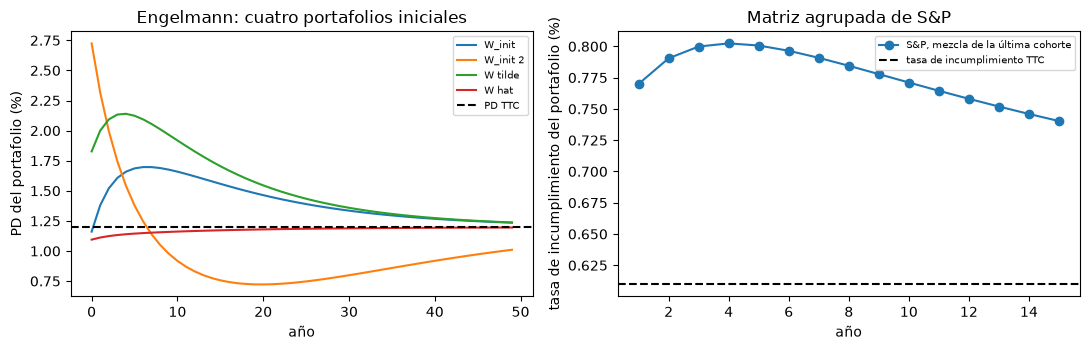

In [10]:
# Dibujar las cuatro trayectorias impresas y la proyección de S&P frente a sus niveles TTC
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
for pf in eng["portfolios"]:
    left.plot(range(len(pf["pd_path"])), 100 * np.array(pf["pd_path"]), label=pf["name"])
left.axhline(100 * ttc_printed["recomputed"], color="black", linestyle="--", label="PD TTC")
left.set_xlabel("año")
left.set_ylabel("PD del portafolio (%)")
left.set_title("Engelmann: cuatro portafolios iniciales")
left.legend(fontsize=7)
right.plot(range(1, 16), 100 * rates, marker="o", label="S&P, mezcla de la última cohorte")
right.axhline(100 * path["ttc"]["default_rate"], color="black", linestyle="--", label="tasa de incumplimiento TTC")
right.set_xlabel("año")
right.set_ylabel("tasa de incumplimiento del portafolio (%)")
right.set_title("Matriz agrupada de S&P")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Resultados

- **La cola, no el promedio.** La PD a través del ciclo de S&P de la mezcla de cohortes es 0,61% y la correlación corporativa de Basilea III a esa PD es 0,21. La tasa de incumplimiento de la LHP es 0,24% en el año mediano, 1,54% en un año del 90%, 5,23% en un año del 99% y 10,9% en un año del 99,9%, 17,9 veces la PD. El 0,77% de la última cohorte implica un factor del ciclo crediticio de -0,77.
- **Una exposición.** Con PD 1%, LGD 45% y vencimiento 2,5 años la correlación es 0,1928, la PD condicional al 99,9% 14,03% (el cuantil de la LHP, igual a la PD condicional de Vasicek), el ajuste por vencimiento 1,2598, K 0,07385 y el ponderador de riesgo 92,3%: 7,385 de capital por 100 de exposición. K reconstruida desde el cuantil de la LHP iguala la del motor.
- **Regímenes.** Con PD de 0,04%, 1% y 10% los ponderadores son 19,65%, 92,32% y 193,1% bajo Basilea III final, lo mismo bajo CRR3, y 18,21%, 97,86% y 204,7% bajo Basilea II. Sobre los pisos Basilea II es exactamente 1,06 veces Basilea III; a 0,04%, entre los dos pisos (0,03% y 0,05%), es 0,927 veces. RAN 21-6 da el número de Basilea III para esta exposición corporativa. Los 162 ponderadores minoristas versionados del caso C01 igualan exactamente el recálculo del motor; un QRRE revolvente con PD 2% y LGD 50% pesa 32,14% bajo Basilea III y CRR3 y 34,06% bajo Basilea II.
- **De las PD a una cartera.** El piso obliga en AAA, AA y A bajo ambas definiciones. La mezcla de cohortes tiene un ponderador de riesgo medio de 57,97% con las PD de la página de incumplimientos (`d2`) y 47,45% con las de la página de transiciones (`d4`), iguales a los valores versionados; el segundo es 0,819 veces el primero, el tema del cuaderno 10.
- **La deriva.** Trayectorias impresas de Engelmann: tres de cuatro portafolios iniciales llegan a la PD TTC (1,198% impresa, 1,1976% recalculada) por un camino no monótono. Uno parte en 1,161%, sube a 1,697% en el año 6 y termina en 1,236% a los 50 años; uno parte en 2,724%, baja a 0,722% en el año 20 y sube a 1,010%; uno parte en 1,827%, sube a 2,14% en el año 4 y baja a 1,237%. En la matriz de S&P la tasa de incumplimiento de la mezcla de la última cohorte parte en 0,770%, sube a 0,802% en el año 4 y es 0,740% en el año 15, aún sobre la tasa TTC de 0,610%.

Lo que este cuaderno no muestra: el piso de producto de Basilea III y el enfoque estandarizado (fuera de los casos IRB de este producto), ni cómo la elección de la PD mueve el capital entre enfoques de calibración (cuaderno 09).

## Resumen

- El ponderador de riesgo IRB es la pérdida en un año del 99,9% de una cartera homogénea grande menos la pérdida esperada, con un ajuste por vencimiento; los dos módulos del motor (IRB y Vasicek) coinciden en él.
- Los regímenes difieren por el piso de PD y por el factor 1,06 de Basilea II; Basilea III final y CRR3 dan el mismo ponderador en una exposición corporativa.
- Una PD de largo plazo bajo el piso pesa como el piso, y la definición de incumplimiento mueve el ponderador de una cartera en 18%.
- Una proyección con una matriz de migración deriva hacia una cartera propia y su PD puede subir y bajar en el camino: un ciclo espurio.

**Qué probar después.** Cambia la LGD del Paso 2 a 0,40 y el vencimiento a 1 y 5 años y lee cómo se mueve K; luego lee el cuaderno 08.

## Referencias

- BCBS, Basel Framework, CRE31 (enfoque IRB: funciones de ponderación de riesgo) y CRE32 (componentes de riesgo: LGD, vencimiento, piso de PD), y CRE30.4 para el factor de escala de Basilea II. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- ESMA, publicación CEREP de calificaciones y transiciones de agencias calificadoras. https://registers.esma.europa.eu/cerep-publication/
- Vasicek, O. (2002), Loan portfolio value, Risk, diciembre de 2002, 160-162.
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), doi 10.1016/S1042-9573(03)00040-8.
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892, ecuaciones 9 y 10, Teorema 1 y sección 4.
- Reglamento (UE) 2024/1623 (CRR3), Artículo 153, para el régimen de la UE.